# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# Replace None with your code
df_cablecars = pd.read_sql( """
SELECT *
FROM customers
WHERE state = 'CA'
  AND creditLimit > 25000
ORDER BY CAST(creditLimit as REAL) DESC;
""", conn)

df_cablecars

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
1,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00
2,321,Corporate Gift Ideas Co.,Brown,Julie,6505551386,7734 Strong St.,,San Francisco,CA,94217,USA,1165,105000.00
3,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
4,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
5,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
6,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
7,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
9,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# Replace None with your code
df_collectcustomers = pd.read_sql( """
SELECT *
FROM customers
WHERE country != 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY customerName;
""",conn)

df_collectcustomers

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,471,"Australian Collectables, Ltd",Clenahan,Sean,61-9-3844-6555,7 Allen Street,,Glen Waverly,Victoria,3150,Australia,1611,60300.00
1,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
2,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
3,415,"Bavarian Collectables Imports, Co.",Donnermeyer,Michael,+49 89 61 08 9555,Hansastr. 15,,Munich,,80686,Germany,1504,77000.00
4,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
5,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
6,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
7,480,"Kremlin Collectables, Co.",Semenov,Alexander,+7 812 293 0521,2 Pobedy Square,,Saint Petersburg,,196143,Russia,,0.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

This query only keeps customers who are not from US, using "!=" and whose customerName has a word "collect" in it using(LIKE '%Collect%').the use of "AND" to ascertain both conditions are met.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Replace None with your code
df_usacredit_bystate = pd.read_sql("""
SELECT state, ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avgCreditLimit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avgCreditLimit DESC; """, conn)
df_usacredit_bystate

,state,avgCreditLimit
0,NH,114200.00
1,NY,89966.67
2,PA,84766.67
3,CA,83854.55
4,NV,71800.00
5,MA,70755.56
6,CT,57350.00
7,NJ,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

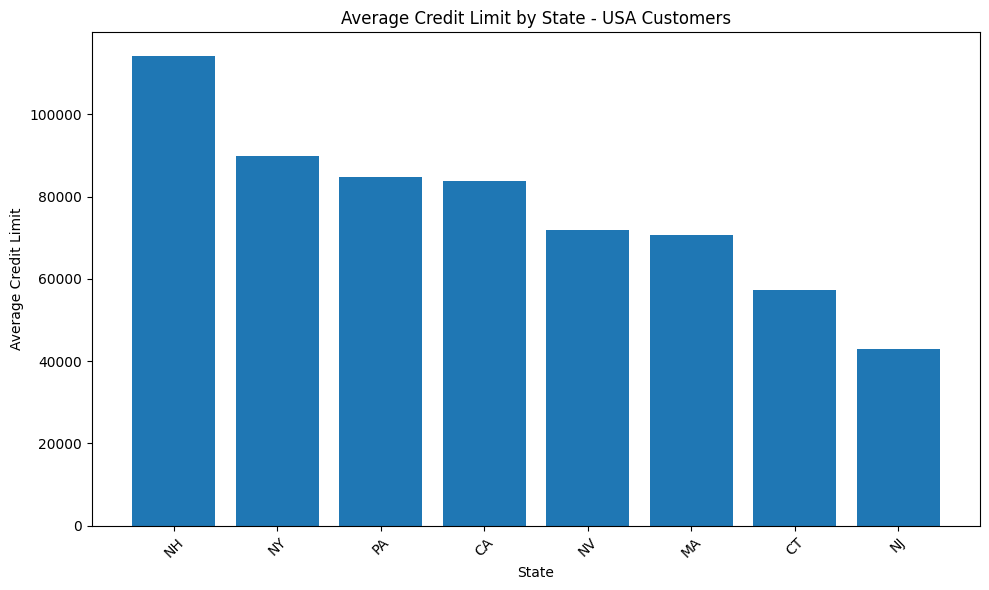

In [5]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
plt.figure(figsize=(10,6))
plt.bar(df_usacredit_bystate['state'], df_usacredit_bystate['avgCreditLimit'])
plt.title('Average Credit Limit by State - USA Customers')
plt.xlabel('State')
plt.ylabel('Average Credit Limit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Replace None with your code
df_top10_customers = pd.read_sql("""
SELECT 
    c.customerNumber,
    c.customerName,
    ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10
""", conn)
df_top10_customers 

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

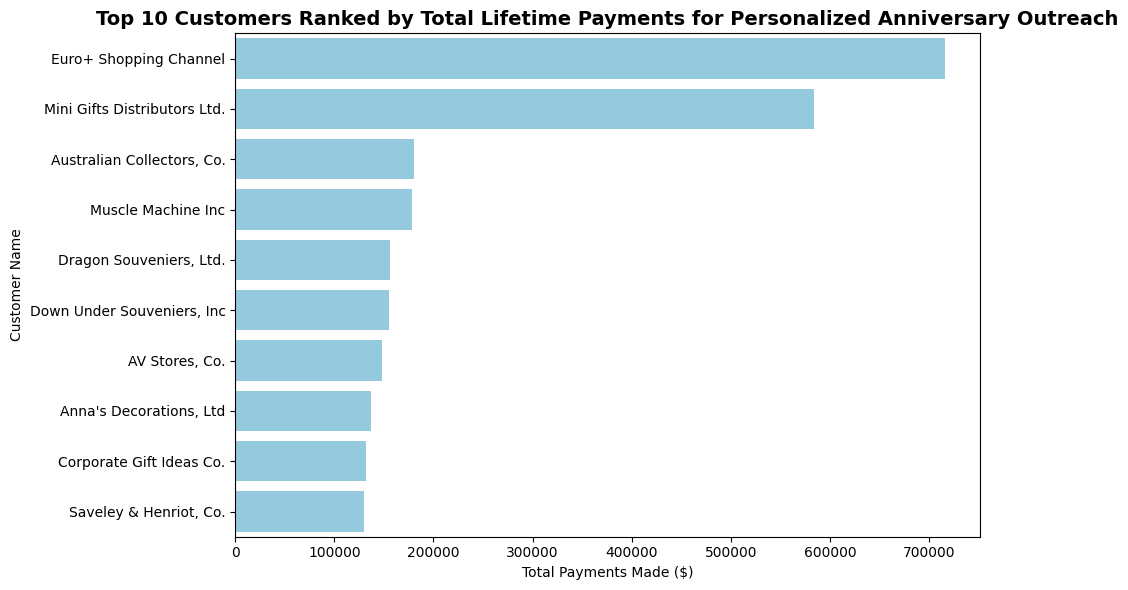

In [7]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.barplot(data=df_top10_customers, x='total_payments', y='customerName', color='skyblue')
plt.title('Top 10 Customers Ranked by Total Lifetime Payments for Personalized Anniversary Outreach', fontsize=14, fontweight='bold')
plt.xlabel('Total Payments Made ($)')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# Replace None with you code
df_popular_products = pd.read_sql("""
SELECT
    c.customerNumber,
    c.customerName,
    p.productCode,
    p.productName,
    SUM(od.quantityOrdered) as total_quantity_purchased
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
JOIN products p ON od.productCode = p.productCode
GROUP BY 
    c.customerNumber, 
    c.customerName, 
    p.productCode, 
    p.productName
HAVING total_quantity_purchased >= 10
ORDER BY total_quantity_purchased ASC
""", conn)

df_popular_products

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Replace None with your code
df_product_line_analysis = pd.read_sql("""
SELECT
    pl.productLine,
    COUNT(DISTINCT p.productCode) as total_products,
    SUM(od.quantityOrdered) as total_quantity_ordered
FROM productlines pl
JOIN products p ON pl.productLine = p.productLine
JOIN orderdetails od ON p.productCode = od.productCode
GROUP BY pl.productLine
ORDER BY total_quantity_ordered DESC
""", conn)
df_product_line_analysis

,productLine,total_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

Text(0.5, 0, 'Quantity')

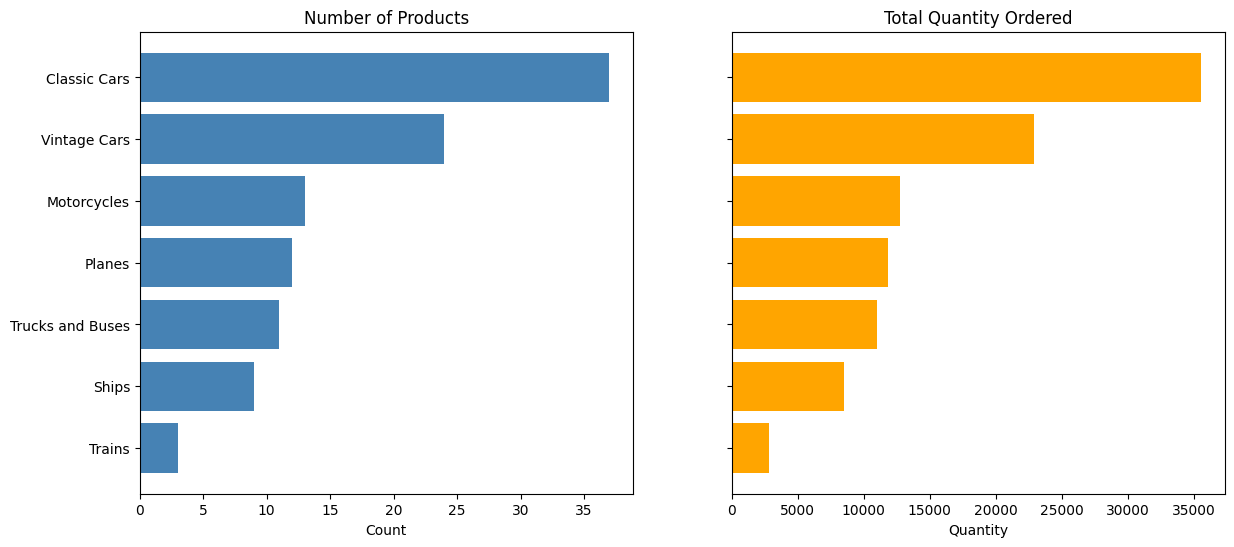

In [10]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,6), sharey=True)

df_sorted = df_product_line_analysis.sort_values('total_products')

ax1.barh(df_sorted['productLine'], df_sorted['total_products'], color='steelblue')
ax1.set_title('Number of Products')
ax1.set_xlabel('Count')

ax2.barh(df_sorted['productLine'], df_sorted['total_quantity_ordered'], color='orange')
ax2.set_title('Total Quantity Ordered')
ax2.set_xlabel('Quantity') 

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

side by side bar chart,helps you see left chart of diversityand right chart of popularity at a glance.you can then spot the diversity versus popularity.Management of the inventory is also made easier by locating  overstocking.you can also be able to compare high potential lines by comparing bars, to ease marketing strategy.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Replace None with your code
df_remote_offices = pd.read_sql("""
SELECT
    e.employeeNumber,
    e.lastName,
    e.firstName,
    e.jobTitle,
    e.officeCode,
    o.city,
    o.country,
    e.reportsTo as supervisorEmployeeNumber,
    CONCAT(m.firstName, ' ', m.lastName) as supervisorName,
    m.jobTitle as supervisorJobTitle
FROM employees e
JOIN offices o ON e.officeCode = o.officeCode
LEFT JOIN employees m ON e.reportsTo = m.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(employeeNumber) < 5
)
ORDER BY e.officeCode, e.employeeNumber
""", conn)

df_remote_offices

,employeeNumber,lastName,firstName,jobTitle,officeCode,city,country,supervisorEmployeeNumber,supervisorName,supervisorJobTitle
0,1188,Firrelli,Julie,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Patterson,Steve,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Tseng,Foon Yue,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,Vanauf,George,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1621,Nishi,Mami,Sales Rep,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
5,1625,Kato,Yoshimi,Sales Rep,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
6,1088,Patterson,William,Sales Manager (APAC),6,Sydney,Australia,1056,Mary Patterson,VP Sales
7,1611,Fixter,Andy,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Marsh,Peter,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1619,King,Tom,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I decided on the subquery by splitting the problem into two equal parts.First I needed to find which offices are small, which means counting employees per office with GROUP BY officeCode and HAVING COUNT(*) < 5. This can't be done in the main query because grouping would hide the individual employee details.Then I used that subquery as a filter list for the main query with WHERE officeCode IN (subquery). The subquery runs first to return the small office codes, and the main query keeps only employees in those offices while adding job titles, office location, and supervisor info through the joins

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

SLIDE 1: Initial Data Exploration Findings

In [14]:
# Begin your code :
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn4)
print(tables)


            name
0   movie_basics
1      directors
2      known_for
3     movie_akas
4  movie_ratings
5        persons
6     principals
7        writers


In [15]:
columns = pd.read_sql("PRAGMA table_info(movie_ratings);", conn4)
print(columns)


   cid           name     type  notnull dflt_value  pk
0    0       movie_id     TEXT        0       None   0
1    1  averagerating     REAL        0       None   0
2    2       numvotes  INTEGER        0       None   0


In [16]:
genre_ratings = pd.read_sql("""
SELECT b.genres AS genre,
       AVG(r.averagerating) AS avg_rating,
       COUNT(*) AS movie_count
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND r.averagerating IS NOT NULL
GROUP BY b.genres
ORDER BY avg_rating DESC;
""", conn4)

print(genre_ratings.head())


                        genre  avg_rating  movie_count
0  Comedy,Documentary,Fantasy         9.4            1
1  Documentary,Family,Musical         9.3            1
2               History,Sport         9.2            1
3               Music,Mystery         9.0            1
4                   Game-Show         9.0            1


In [17]:
#SLIDE 2:RUNTIME TRENDS
runtime_trends = pd.read_sql("""
SELECT start_year, AVG(runtime_minutes) AS avg_runtime
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
  AND runtime_minutes IS NOT NULL
GROUP BY start_year
ORDER BY start_year;
""", conn4)

print(runtime_trends)


   start_year  avg_runtime
0        2010    85.495694
1        2011    86.410106
2        2012    89.208856
3        2013    84.931670
4        2014    84.541500
5        2015    85.407108
6        2016    84.974249
7        2017    85.732214
8        2018    87.661099
9        2019    90.887358


### Load in data from the relevant directory and inspect the dataframe.
- inspect NaNs, datatypes, and summary statistics

In [18]:
pd.read_sql("PRAGMA table_info(persons);", conn4)


,cid,name,type,notnull,dflt_value,pk
0,0,person_id,TEXT,0,None,0
1,1,primary_name,TEXT,0,None,0
2,2,birth_year,REAL,0,None,0
3,3,death_year,REAL,0,None,0
4,4,primary_profession,TEXT,0,None,0


In [19]:
#DIRECTORS
top_directors = pd.read_sql("""
SELECT p.primary_name AS director_name,
       AVG(r.averagerating) AS avg_rating,
       COUNT(*) AS films
FROM directors d
JOIN persons p ON d.person_id = p.person_id
JOIN movie_basics b ON d.movie_id = b.movie_id
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND r.averagerating IS NOT NULL
GROUP BY p.primary_name
HAVING COUNT(*) >= 3
ORDER BY avg_rating DESC
LIMIT 10;
""", conn4)

print(top_directors)


              director_name  avg_rating  films
0            Tyler Chandler         9.7      3
1              Julie Simone         9.6      3
2               Lauren Ross         9.5      3
3             John Griesser         9.5      3
4             Jean Griesser         9.5      3
5            D. Todd Deeken         9.5      4
6  Triantafyllia Dimopoulou         9.4      3
7               Roy Zafrani         9.4      3
8              Milan Lisica         9.4      3
9        Miguel I. González         9.4      3


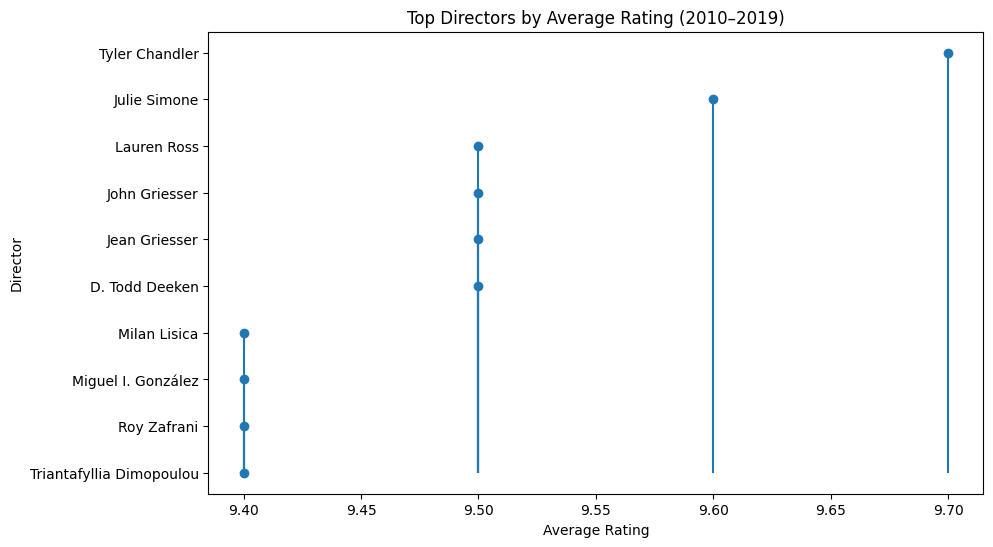

In [20]:
sorted_directors = top_directors.sort_values("avg_rating")

plt.figure(figsize=(10,6))
plt.stem(sorted_directors["avg_rating"], sorted_directors["director_name"], basefmt=" ")
plt.title("Top Directors by Average Rating (2010–2019)")
plt.xlabel("Average Rating")
plt.ylabel("Director")
plt.show()


In [21]:
#RATINGS VS POPULARITY
genre_popularity = pd.read_sql("""
SELECT b.genres AS genre,
       AVG(r.averagerating) AS avg_rating,
       SUM(r.numvotes) AS total_votes
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND r.averagerating IS NOT NULL
  AND r.numvotes IS NOT NULL
GROUP BY b.genres
ORDER BY avg_rating DESC;
""", conn4)

print(genre_popularity.head())


                        genre  avg_rating  total_votes
0  Comedy,Documentary,Fantasy         9.4            5
1  Documentary,Family,Musical         9.3           19
2               History,Sport         9.2            5
3               Music,Mystery         9.0            5
4                   Game-Show         9.0            7


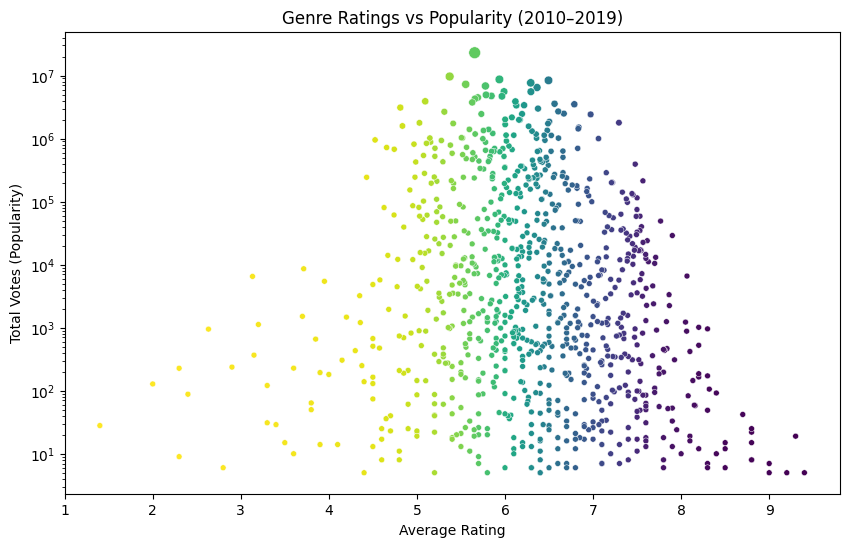

In [22]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=genre_popularity,
                x="avg_rating", y="total_votes",
                hue="genre", size="total_votes",
                palette="viridis", legend=False)
plt.title("Genre Ratings vs Popularity (2010–2019)")
plt.xlabel("Average Rating")
plt.ylabel("Total Votes (Popularity)")
plt.yscale("log")  
plt.show()


**SLIDE 4: SUMMARY**

** Genre Ratings**

Drama and Documentary consistently score highest.

Action and Comedy attract large audiences but lower ratings.

Insight: Critical acclaim vs. mass appeal — balance matters.

**Runtime Trends**

Average runtime has been rising across the decade.

Longer films dominate prestige genres, but risk audience fatigue.

Insight: Runtime should match genre expectations — don’t overextend comedies.

**Directors**

Certain directors (≥3 films) deliver consistently high ratings.

Reliable creative leadership correlates with stronger audience reception.

Insight: Invest in proven directors for critical success.

**Slide Ratings vs Popularity (Scatter Plot)**

Drama = high ratings + high votes → prestige + reach.

Documentary = high ratings, low votes → niche but valuable.

Action = high votes, lower ratings → commercial appeal.

Insight: Strategic trade‑off: prestige vs. popularity.

** BUSSINESS QUESTION**
How can genre, runtime, and director choice guide production
 decisions to maximize both critical success and audience reach?

In [23]:
#BUSINESS QUESTION:
genre_runtime_ratings = pd.read_sql("""
SELECT b.genres AS genre,
       AVG(b.runtime_minutes) AS avg_runtime,
       AVG(r.averagerating) AS avg_rating,
       COUNT(*) AS movie_count
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND r.averagerating IS NOT NULL
GROUP BY b.genres
ORDER BY avg_rating DESC;
""", conn4)

print(genre_runtime_ratings.head())


                        genre  avg_runtime  avg_rating  movie_count
0  Comedy,Documentary,Fantasy         70.0         9.4            1
1  Documentary,Family,Musical         59.0         9.3            1
2                   Game-Show        130.0         9.0            1
3                 Drama,Short         18.0         8.8            1
4      Documentary,News,Sport         85.0         8.8            1


Null Handling 
Normalization
Runtime Cleaning: Filter outliers.  
.Join Duplication Risk 
Akas Duplication
Aggregation


In [24]:
# Load tables from your database connection (conn4)
movie_basics = pd.read_sql("SELECT * FROM movie_basics;", conn4)
movie_ratings = pd.read_sql("SELECT * FROM movie_ratings;", conn4)
persons = pd.read_sql("SELECT * FROM persons;", conn4)

In [25]:
# 1. Handle nulls
movie_basics = movie_basics.dropna(subset=["runtime_minutes", "genres"])
movie_ratings = movie_ratings.dropna(subset=["averagerating", "numvotes"])

In [26]:
# 2. Normalize genre names
movie_basics["genres"] = movie_basics["genres"].replace({
    "Sci-Fi": "Science Fiction",
    "sci fi": "Science Fiction"
})

In [27]:
# 3. Deduplicate movies
movie_basics = movie_basics.drop_duplicates(subset=["primary_title", "start_year"])

In [28]:
# 4. Standardize runtime
movie_basics["runtime_minutes"] = pd.to_numeric(movie_basics["runtime_minutes"], errors="coerce")

In [29]:
# 5. Consistent personnel names
persons["primary_name"] = persons["primary_name"].str.strip().str.title()

In [30]:
# Merge cleaned tables for analysis
cleaned_data = movie_basics.merge(movie_ratings, on="movie_id")

In [31]:
# Quick check: average rating by genre after cleaning
genre_summary = cleaned_data.groupby("genres")["averagerating"].mean().sort_values(ascending=False)
print(genre_summary.head(10))

genres
Comedy,Documentary,Fantasy     9.4
Documentary,Family,Musical     9.3
Game-Show                      9.0
Documentary,News,Sport         8.8
Documentary,News,Reality-TV    8.8
Drama,Short                    8.8
Action,Adventure,Musical       8.7
Biography,History,Music        8.5
Adventure,Crime                8.5
Music,Musical,Romance          8.4
Name: averagerating, dtype: float64


In [32]:
conn4.close()